# 原版 DDMPY 0930 与 MOOSE 三维有限元：实际结果对比

本 notebook 对应原包自带的 **`Examples/Horizontal well existing tensile and shear.ipynb`**。
原版 DDMPY 源码未修改。MOOSE 独立求解三个位移分量，再由井上位移计算轴向应变与应变率。

**打开即可阅读已执行的表格和图片。** 默认重新运行完整原版 DDMPY，并读取本次已经完成的 30 帧 MOOSE 结果。
将后面的 `RUN_MOOSE=True` 可重新进行全部有限元计算（本机 8 个 MPI 进程的已完成运行约 7 分钟，峰值内存较高）。
保存的输出由本机 base Python / IPython 顺序执行各代码单元生成，并非手工填写。

原例：300 m × 300 m 矩形，中心 (150,130,-30) m，strike=0°、dip=90°；300 个井点，10 m 标距。
30 帧中 S1 从 0 增至 1 mm，张开量为 S1/10，S2=0。按原图轴标签将 0–60 解释为分钟，计算时统一换为秒。
原版的 90° 微调在兼容计算中保留。

In [1]:
from pathlib import Path
import sys, json, hashlib, time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from dataclasses import asdict, replace

# 移动工作区后可修改 ROOT。
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'fibeRIS').is_dir() and (p/'scripts/numerical_ddm').is_dir()),
            Path('/rcp/rcp42/home/shenyaojin/Documents/bakken_mariner'))
sys.path[:0] = [str(ROOT), str(ROOT/'fibeRIS/src'), str(ROOT/'scripts/numerical_ddm')]
OUT = ROOT/'output/numerical_ddm'
CASE = OUT/'notebook_existing_tensile_shear'
SAVED = CASE/'full_h20_t0.2_L2400_refined_recycled'
ASSETS = CASE/'review_notebook_figures'
ASSETS.mkdir(parents=True, exist_ok=True)
pd.set_option('display.precision', 6)

manifest = json.loads((CASE/'reference_sha256.json').read_text())
for name, digest in manifest.items():
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest() == digest, name
print(f'工作区：{ROOT}')
print(f'原始参考文件：{len(manifest)} 个，SHA256 均未改变。')

工作区：/rcp/rcp42/home/shenyaojin/Documents/bakken_mariner
原始参考文件：9 个，SHA256 均未改变。


## 1. 实际运行原版 0930 DDMPY

下面保留原例的建模方式。`Element.mu` 表示泊松比，原版位移解不需要输入杨氏模量。
原版全局裂缝对象内部保存局部位移，比较前会转换到全局坐标。
原例 `take_time_diff()` 给出后向区间差分，首列为 0；本文件保留这个兼容结果，并另列点导数。

In [2]:
from scripts.tensile_fault.data_transfer.from_pc import DDMpy_0930 as ddmpy

control_points = np.array([[0.,0.,-30.], [300.,0.,-30.]])
well = ddmpy.Well.set_well_by_points(control_points, N=300, smooth=31)
well.gauge_length = 10.
fracture = ddmpy.DynamicFracture.GlobalRectangularFracture()
fracture.set_global_coors(0,90,150,130,-30)
times_minutes = np.linspace(0,60,30)
length = np.ones(30)*300
S1 = np.linspace(0,1e-3,30)
fracture.define_LHW(times_minutes, length, length, S1*.1, S1=S1, S2=None)
fracture.set_monitor_wells(well)

started = time.perf_counter()
fracture.calculate()
ddmpy_calculate_seconds = time.perf_counter()-started
original_data = fracture.gather_strain_data()[0]
reference_strain = original_data.data.copy()
original_data.take_time_diff()
reference_rate = original_data.data.copy()/60.  # 每分钟 -> 每秒
times_seconds = times_minutes*60.
points = np.column_stack([well.x,well.y,well.z])
md = well.mds.copy()
R = ddmpy.Fracture.coor_global_to_local(*np.eye(3), fracture.strike, fracture.dip)
reference_u = np.array([np.column_stack([f.monitor_wells[0].u1,
    f.monitor_wells[0].u2,f.monitor_wells[0].u3]) @ R for f in fracture.fractures])

frozen = np.load(CASE/'original_0930.npz')
np.testing.assert_allclose(reference_u, frozen['u'], rtol=1e-12, atol=1e-17)
np.testing.assert_allclose(reference_strain, frozen['strain'], rtol=1e-12, atol=1e-17)
print(f'原版 DDMPY：实际完成 {len(times_seconds)} 帧 × {len(points)} 井点。')
print(f'本次 calculate() 耗时：{ddmpy_calculate_seconds:.6f} s；与冻结参考一致。')

原版 DDMPY：实际完成 30 帧 × 300 井点。
本次 calculate() 耗时：0.142015 s；与冻结参考一致。


## 2. fibeRIS → MOOSE：数值设置与实际有限元结果

三维均匀各向同性小应变弹性，E=30 GPa、ν=0.3。
有限矩形薄层的本征应变为 ε*33=width/t、ε*13=S1/(2t)、ε*23=S2/(2t)。
矩形高度、给定张开量、数值薄层厚度分别定义。
外边界六面位移为零，未使用 DDMPY 解析边界；位移由 HEX27 三维有限元计算。

几何和井直接从原版对象导入；数值设置独立配置。固定几何时可复用刚度矩阵和 PETSc 初始猜测。
初始猜测的子空间来自此前的有限元解，每个载荷仍按原容差检查平衡；DDMPY 位移不进入该路径。
该例 30 帧包含初始零载荷状态及 29 个非零平衡状态。

In [3]:
from fiberis.moose.numerical_ddm import NumericalConfig, from_ddmpy, time_derivative

RUN_MOOSE = False  # True：重新求解；False：读取已完成的真实 MOOSE 运行
config = NumericalConfig(
    executable=str(ROOT/'moose_env/moose/modules/combined/combined-opt'),
    output_directory=str(CASE/'review_notebook_rerun'),
    youngs_modulus=30e9, poissons_ratio=.3,
    half_extent=2400, core_extent=180, mesh_size=20,
    band_thickness=.2, band_cells=2, processors=8,
    mpiexec=str(Path.home()/'miniforge/envs/moose/bin/mpiexec'),
    local_refinements=((0,-160.,-100.,5.),(1,-30.,30.,10.),(2,-40.,40.,2.5)),
    reuse_constant_jacobian=True, recycle_krylov_guess=True)
numerical = from_ddmpy(fracture.fractures[-1], config)
factors = S1/S1[-1]
# 此快捷时序要求固定几何、各跳跃分量共用幅度历史。
history_jumps = np.array([[-f.elements[0].S1,-f.elements[0].S2,-f.elements[0].width]
                          for f in fracture.fractures])
np.testing.assert_allclose(history_jumps,factors[:,None]*history_jumps[-1],rtol=1e-12,atol=1e-17)
np.testing.assert_allclose([[f.elements[0].length,f.elements[0].height] for f in fracture.fractures],
                          np.broadcast_to([300.,300.],(30,2)))

if RUN_MOOSE:
    u = numerical.sample_history(points,times_seconds,factors)
    result_directory = Path(config.output_directory)
else:
    result_directory = SAVED
    saved = np.load(SAVED/'displacement_history.npz')
    saved_model = json.loads((SAVED/'model.json').read_text())
    saved_frame = json.loads((SAVED/'global_frame.json').read_text())
    numerical_R,numerical_origin = numerical.frame()
    np.testing.assert_allclose(numerical_R,saved_frame['global_to_local_rotation'],rtol=0,atol=1e-14)
    np.testing.assert_allclose(numerical_origin,saved_frame['global_origin_m'],rtol=0,atol=1e-12)
    for key in ['youngs_modulus','poissons_ratio','half_extent','core_extent','mesh_size',
                'band_thickness','band_cells','local_refinements','growth','linear_tolerance']:
        np.testing.assert_allclose(asdict(config)[key],saved_model['config'][key],rtol=0,atol=0)
    for key in ['order','quadrature','reuse_constant_jacobian','recycle_krylov_guess']:
        assert asdict(config)[key]==saved_model['config'][key],key
    np.testing.assert_allclose(saved['points'],points,rtol=0,atol=1e-10)
    np.testing.assert_allclose(saved['times'],times_seconds)
    np.testing.assert_allclose(saved['factors'],factors)
    e = numerical.elements[0]
    old_e = saved_model['elements'][0]
    for key in ['length','height','width','S1','S2','abs_x1','abs_x2','abs_x3','mu']:
        np.testing.assert_allclose(getattr(e,key),old_e[key],rtol=1e-13,atol=1e-17)
    u = saved['displacement']

run = json.loads((result_directory/'run.json').read_text())
assert run['success'] and u.shape==(30,300,3)
print('本格重新运行 MOOSE：', RUN_MOOSE)
print('实际数值结果目录：',result_directory)
print('实际命令：',(result_directory/'command.txt').read_text().strip())
case_R,case_origin = numerical.frame()
print('接收点到裂缝面的最小法向距离 (m)：',float(abs(((points-case_origin)@case_R.T)[:,2]).min()))
print('数值薄层半厚度 (m)：',config.band_thickness/2)
print(f"已完成的 MOOSE 运行：{run['elapsed_seconds']:.3f} s，{run['processors']} MPI 进程，30 帧。")

本格重新运行 MOOSE： False
实际数值结果目录： /rcp/rcp42/home/shenyaojin/Documents/bakken_mariner/output/numerical_ddm/notebook_existing_tensile_shear/full_h20_t0.2_L2400_refined_recycled
实际命令： /rcp/rcp42/home/shenyaojin/miniforge/envs/moose/bin/mpiexec -n 8 /rcp/rcp42/home/shenyaojin/Documents/bakken_mariner/moose_env/moose/modules/combined/combined-opt -i model.i --n-threads=1
接收点到裂缝面的最小法向距离 (m)： 0.501671989966522
数值薄层半厚度 (m)： 0.1
已完成的 MOOSE 运行：426.708 s，8 MPI 进程，30 帧。


## 3. 相同的井观测算子与量化误差

先取井上的位移，再做切向投影、空间差分和原例的按点数标距平均。
没有用某个笛卡尔应变分量代替完整井响应。所有 300 个点和 30 帧都进入统计。
相对 L2 使用整个数组的范数；峰值归一化最大误差使用参考全信号峰值，避免近零点逐点相除。

In [4]:
from run_validation import metrics

w = numerical.monitor_wells[0]
strain_frames = []
for frame_u in u:
    w.u1,w.u2,w.u3 = frame_u.T
    w.calculate_strain()
    strain_frames.append(w.strain.copy())
strain = np.column_stack(strain_frames)
rate = np.column_stack([np.zeros(len(md)),np.diff(strain,axis=1)/np.diff(times_seconds)])
point_rate = time_derivative(strain,times_seconds)
reference_point_rate = time_derivative(reference_strain,times_seconds)
rows = []
for name,value,ref,unit in [
    ('全部全局位移分量',u,reference_u,'m'),
    ('井轴向应变',strain,reference_strain,'1'),
    ('原版兼容应变率',rate,reference_rate,'1/s'),
    ('二阶点导数应变率',point_rate,reference_point_rate,'1/s')]:
    m = metrics(value,ref)
    rows.append({'量':name,'相对 L2 (%)':100*m['relative_l2'],
                 '峰值归一化最大误差 (%)':100*m['peak_normalized_max'],
                 '最大绝对误差':m['max_absolute'],'单位':unit})
display(pd.DataFrame(rows).set_index('量'))
print('初始零载荷最大位移：',float(abs(u[0]).max()),'m')

初始零载荷最大位移： 0.0 m


,相对 L2 (%),峰值归一化最大误差 (%),最大绝对误差,单位
量,,,,
全部全局位移分量,0.041080,0.034814,1.749186e-07,m
井轴向应变,0.260437,0.191023,2.310833e-08,1
原版兼容应变率,0.260437,0.191023,6.418982e-12,1/s
二阶点导数应变率,0.260437,0.191023,6.418982e-12,1/s


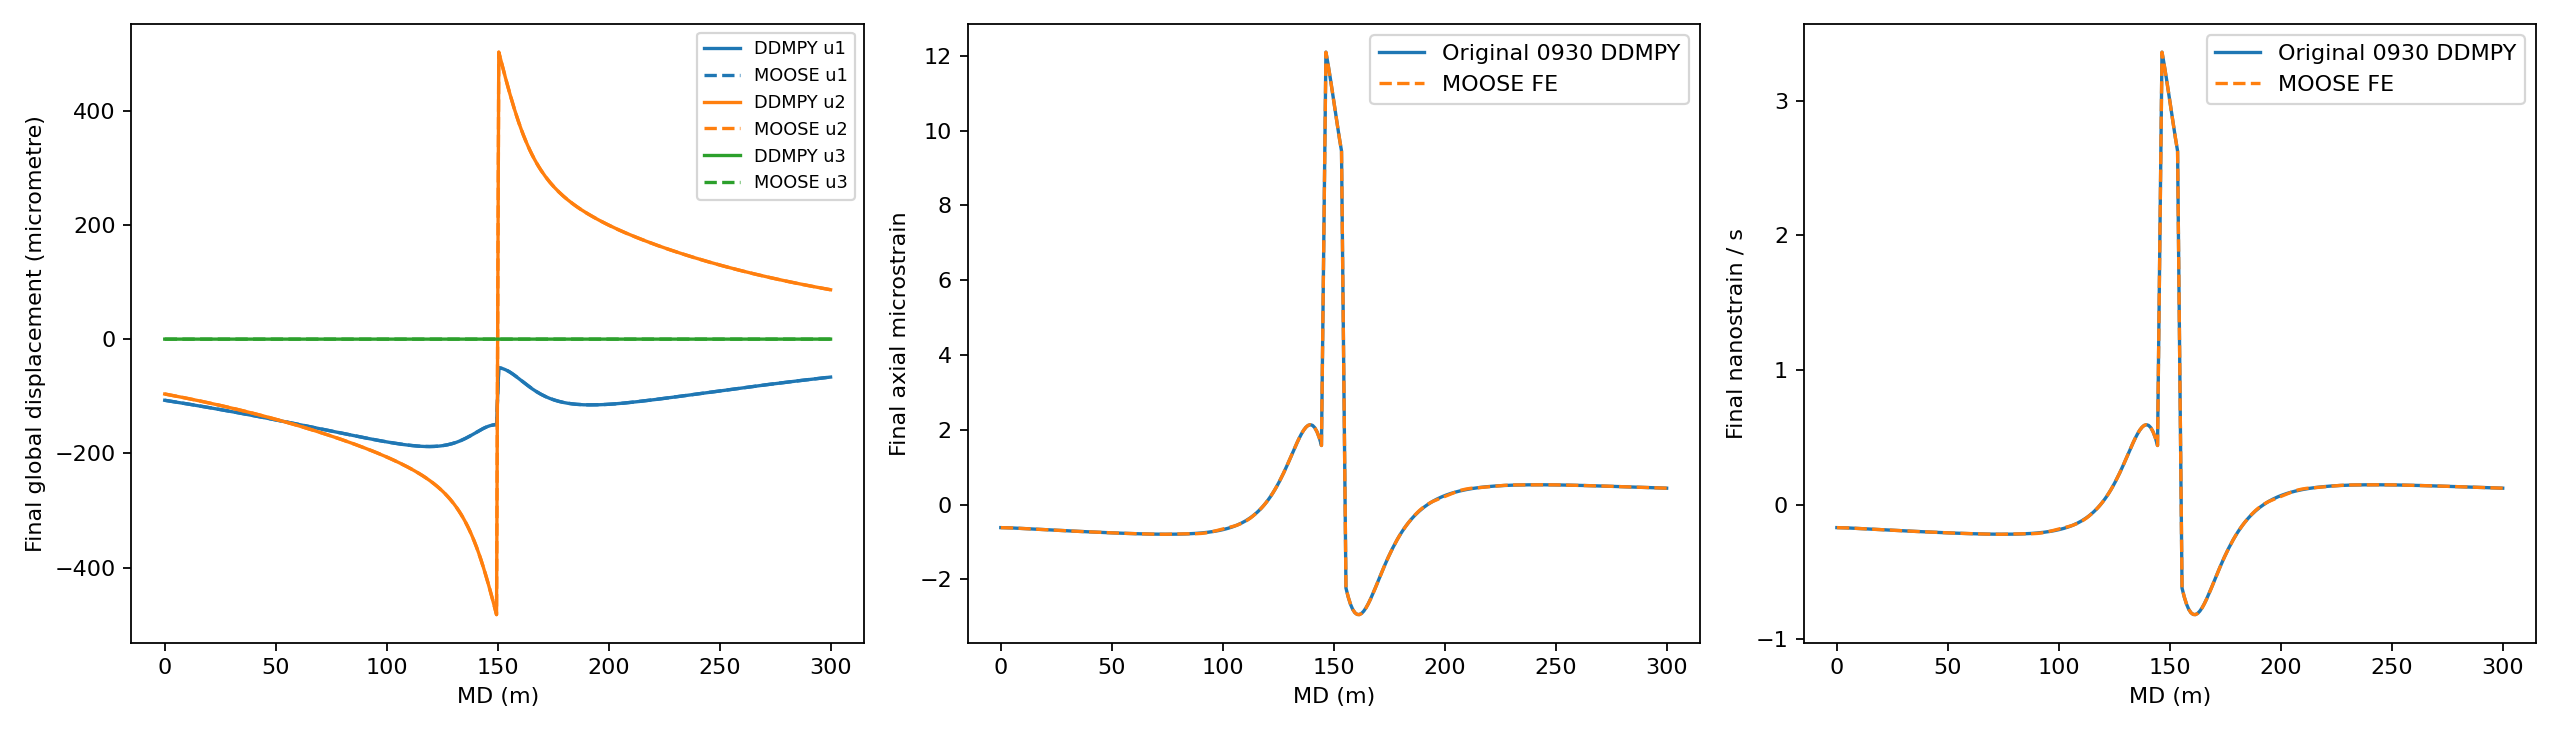

In [5]:
fig,axes = plt.subplots(1,3,figsize=(16,4.6))
for k in range(3):
    line, = axes[0].plot(md,reference_u[-1,:,k]*1e6,label=f'DDMPY u{k+1}')
    axes[0].plot(md,u[-1,:,k]*1e6,'--',color=line.get_color(),label=f'MOOSE u{k+1}')
axes[0].set(xlabel='MD (m)',ylabel='Final global displacement (micrometre)')
axes[0].legend(fontsize=8)
for ax,num,ref,scale,label in [
    (axes[1],strain,reference_strain,1e6,'Final axial microstrain'),
    (axes[2],rate,reference_rate,1e9,'Final nanostrain / s')]:
    ax.plot(md,ref[:,-1]*scale,label='Original 0930 DDMPY')
    ax.plot(md,num[:,-1]*scale,'--',label='MOOSE FE')
    ax.set(xlabel='MD (m)',ylabel=label)
    ax.legend()
fig.tight_layout()
fig.savefig(ASSETS/'profiles.png',dpi=160)
fig.savefig(ASSETS/'profiles.pdf')
plt.close(fig)
display(Image(filename=str(ASSETS/'profiles.png')))

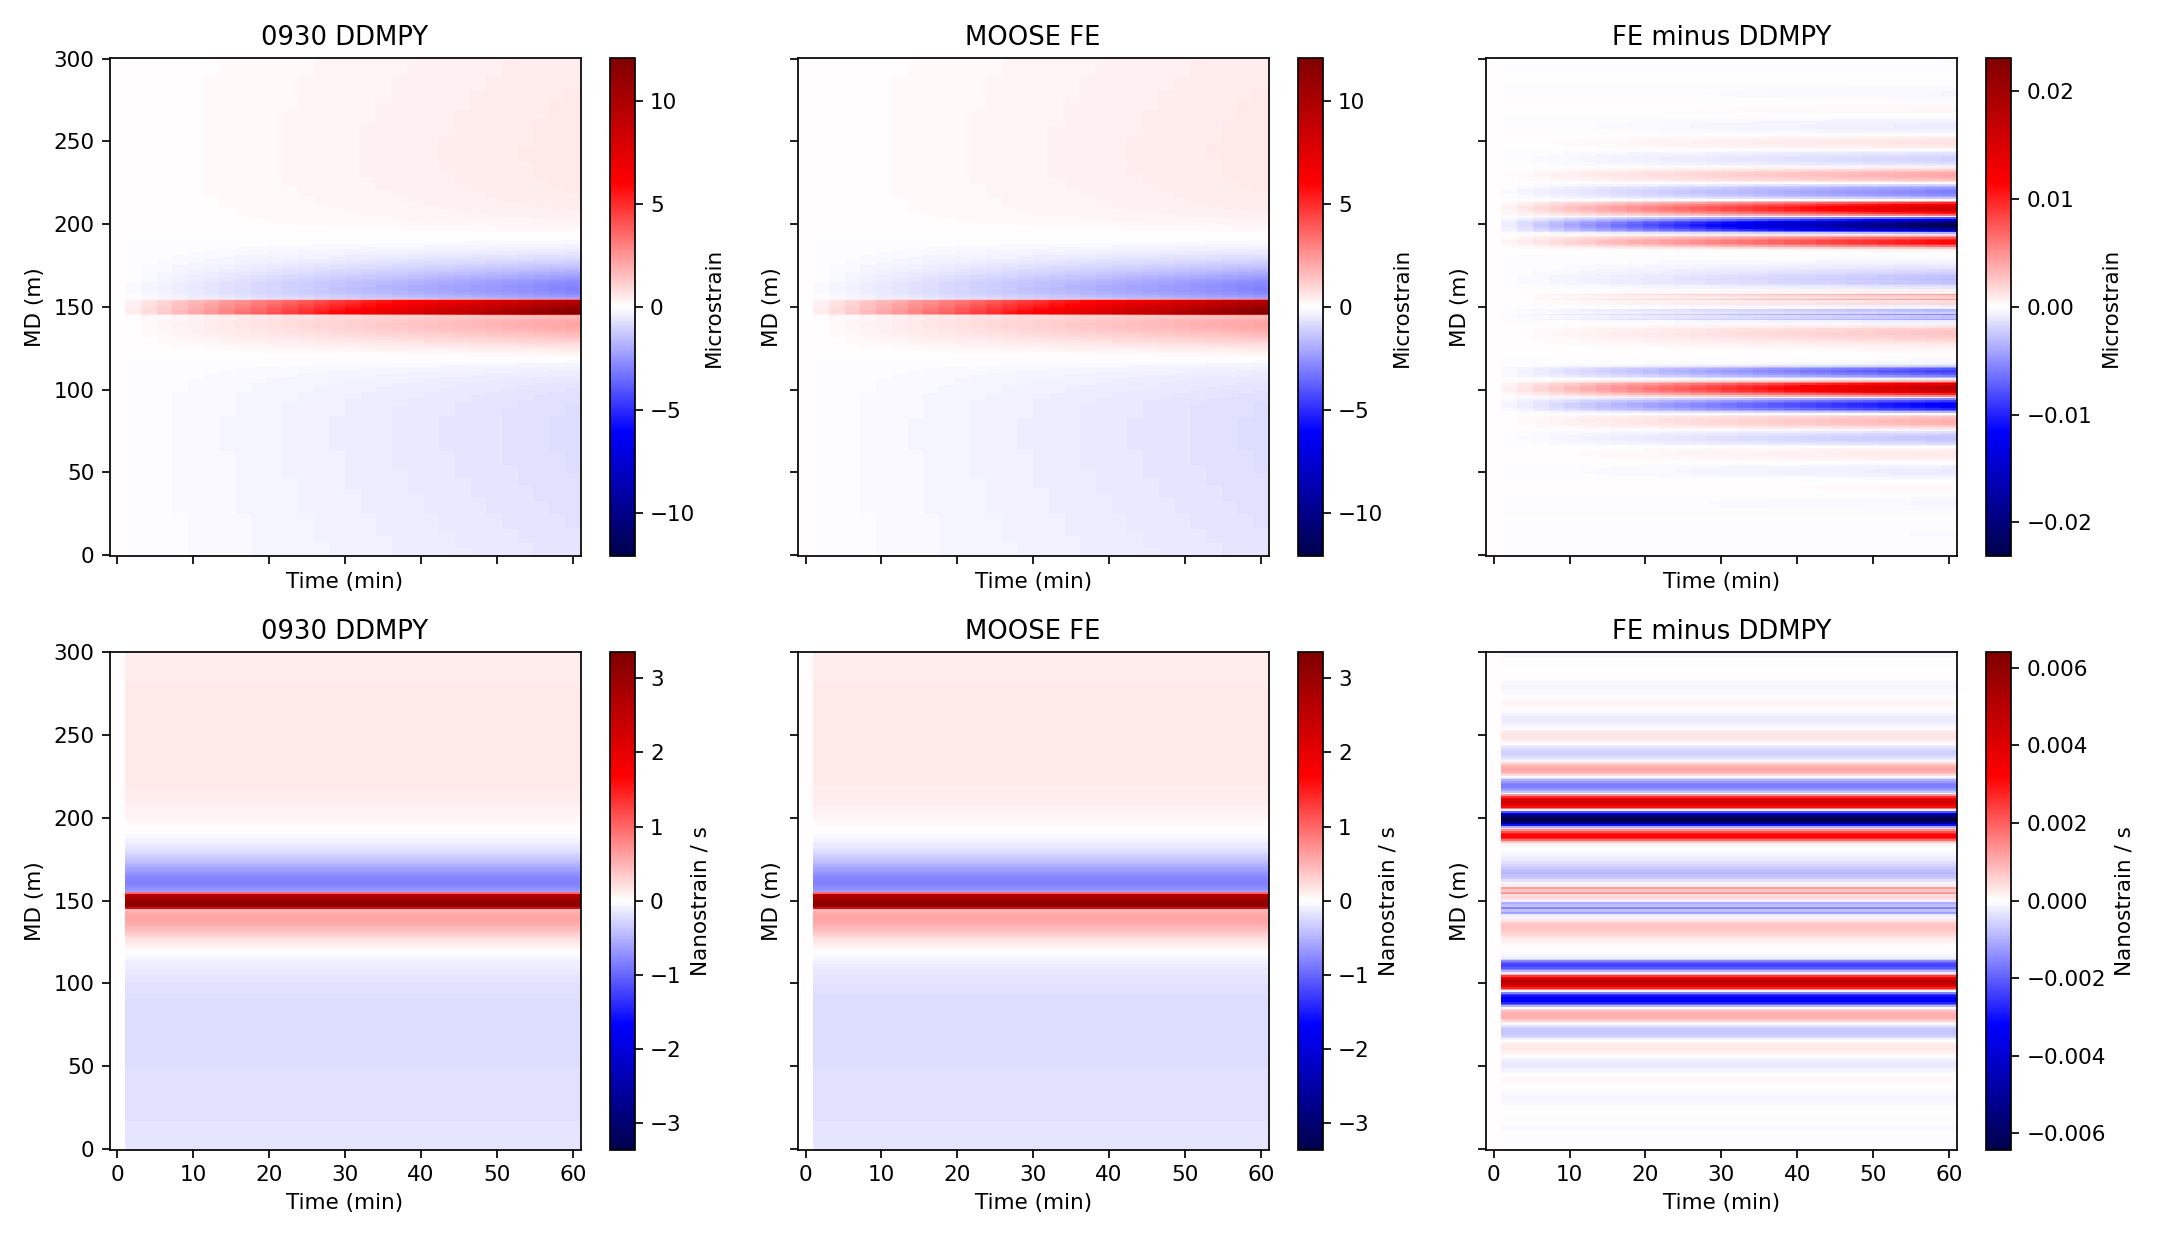

In [6]:
fig,axes = plt.subplots(2,3,figsize=(14,8),sharex=True,sharey=True)
for row,(num,ref,label,scale) in enumerate([
    (strain,reference_strain,'Microstrain',1e6),
    (rate,reference_rate,'Nanostrain / s',1e9)]):
    limit = abs(ref).max()*scale
    for ax,value,title in zip(axes[row],[ref,num,num-ref],['0930 DDMPY','MOOSE FE','FE minus DDMPY']):
        color_limit = max(abs(value).max()*scale,1e-15) if title=='FE minus DDMPY' else limit
        im = ax.pcolormesh(times_minutes,md,value*scale,shading='auto',cmap='seismic',
                           vmin=-color_limit,vmax=color_limit)
        ax.set(title=title,xlabel='Time (min)',ylabel='MD (m)')
        fig.colorbar(im,ax=ax,label=label)
fig.tight_layout()
fig.savefig(ASSETS/'waterfalls.png',dpi=155)
fig.savefig(ASSETS/'waterfalls.pdf')
plt.close(fig)
display(Image(filename=str(ASSETS/'waterfalls.png')))

误差面板采用独立色标，便于看清小残差。原版首帧应变率人为设为 0；
点导数的首帧通常不为 0，两种定义分别报告。穿面井的尖峰是此特定离散轨迹和10 m标距的响应，不能视为尖端应力精度验证。

## 4. 两者的计算成本

DDMPY 是均匀无限全空间下给定位移间断的解析计算，适合该参考问题的快速正演。
MOOSE 在有限域内组装和求解三维有限元系统，付出网格、边界和薄层正则化误差及计算成本。
这里仅实现和验证纯弹性；额外流动、接触或非均匀材料的精度不在本次结论中。

计时范围有所不同：DDMPY 为本 notebook 刚执行的 `calculate()`，包含其井应变处理；
MOOSE 为记录的外部求解进程，包含网格和求解，Python后处理另行执行。两者均为单次实测，不是专门的并行性能基准。
RSS 是操作系统报告的子进程高水位，**不能作为全部MPI进程内存之和**。

In [7]:
import re
log = re.sub(r'\x1b\[[0-9;]*m','',(result_directory/'log.txt').read_text())
dofs = int(re.search(r'Num DOFs:\s+(\d+)',log).group(1))
cost = pd.DataFrame([
    {'方法':'原版 DDMPY 0930','实测墙钟秒':ddmpy_calculate_seconds,'进程数':1,
     '未知量自由度':np.nan,'子进程 CPU 秒':np.nan,'子进程最大 RSS GiB':np.nan},
    {'方法':'MOOSE 三维 FE','实测墙钟秒':run['elapsed_seconds'],'进程数':run['processors'],
     '未知量自由度':dofs,'子进程 CPU 秒':run['cpu_seconds'],
     '子进程最大 RSS GiB':run['child_maxrss_kib']/1024**2}])
display(cost.set_index('方法'))
paths = json.loads((CASE/'solver_path_comparison.json').read_text())
print('与独立三帧有限元求解的位移相对差：',paths['versus_independent_pilot']['displacement']['relative_l2'])
print('与旧长时序已完成帧的位移相对差：',paths['versus_completed_cold_frames']['relative_l2'])

与独立三帧有限元求解的位移相对差： 2.4104890063224033e-09
与旧长时序已完成帧的位移相对差： 4.21707944077007e-10


,实测墙钟秒,进程数,未知量自由度,子进程 CPU 秒,子进程最大 RSS GiB
方法,,,,,
原版 DDMPY 0930,0.142015,1,NaN,NaN,NaN
MOOSE 三维 FE,426.708428,8,3388695.0,3402.066564,6.914864


## 5. 真实收敛和扩展验证

独立基准：100 m × 60 m、张开1 mm、ν=0.3、E=30 GPa；101个固定井点为 x=-100:2:100、y=17、z=40 m。
三个网格层级、独立域大小、薄层厚度、层内单元数和积分阶数都实际求解过。
推荐7.5 m基准网格：共同观测算子下应变L2约0.361%；若计入空间差分及端点规则、对照更细解析采样导数，总应变误差约0.798%。
位移误差轻微非单调，不能将边界、薄层与离散误差的抵消解释成各误差项单独达标。

,位移 L2 (%),应变 L2 (%),应变峰值归一化最大误差 (%),DOFs,墙钟秒
算例,,,,,
opening_h20_L800_t2,0.277606,5.715465,10.299725,637023,36.855282
opening_h10_L800_t2,0.048701,0.959025,1.731592,1929075,104.689209
opening_h7p5_L800_t2,0.054021,0.361365,0.662734,3742515,267.974112
opening_h10_L400_t2,0.393511,1.055761,2.021281,1440747,72.629263
opening_h10_L1600_t2,0.030289,0.957581,1.692139,2516859,149.771495
opening_h10_L800_t1,0.049133,0.964462,1.748697,1929075,99.497040
opening_h10_L800_t4,0.046710,0.948003,1.604541,1929075,112.261346
opening_h10_L800_t2_b1,0.048700,0.959020,1.731554,1885725,103.321144
opening_h10_L800_t2_b4,0.048701,0.959025,1.731599,2015775,117.300452


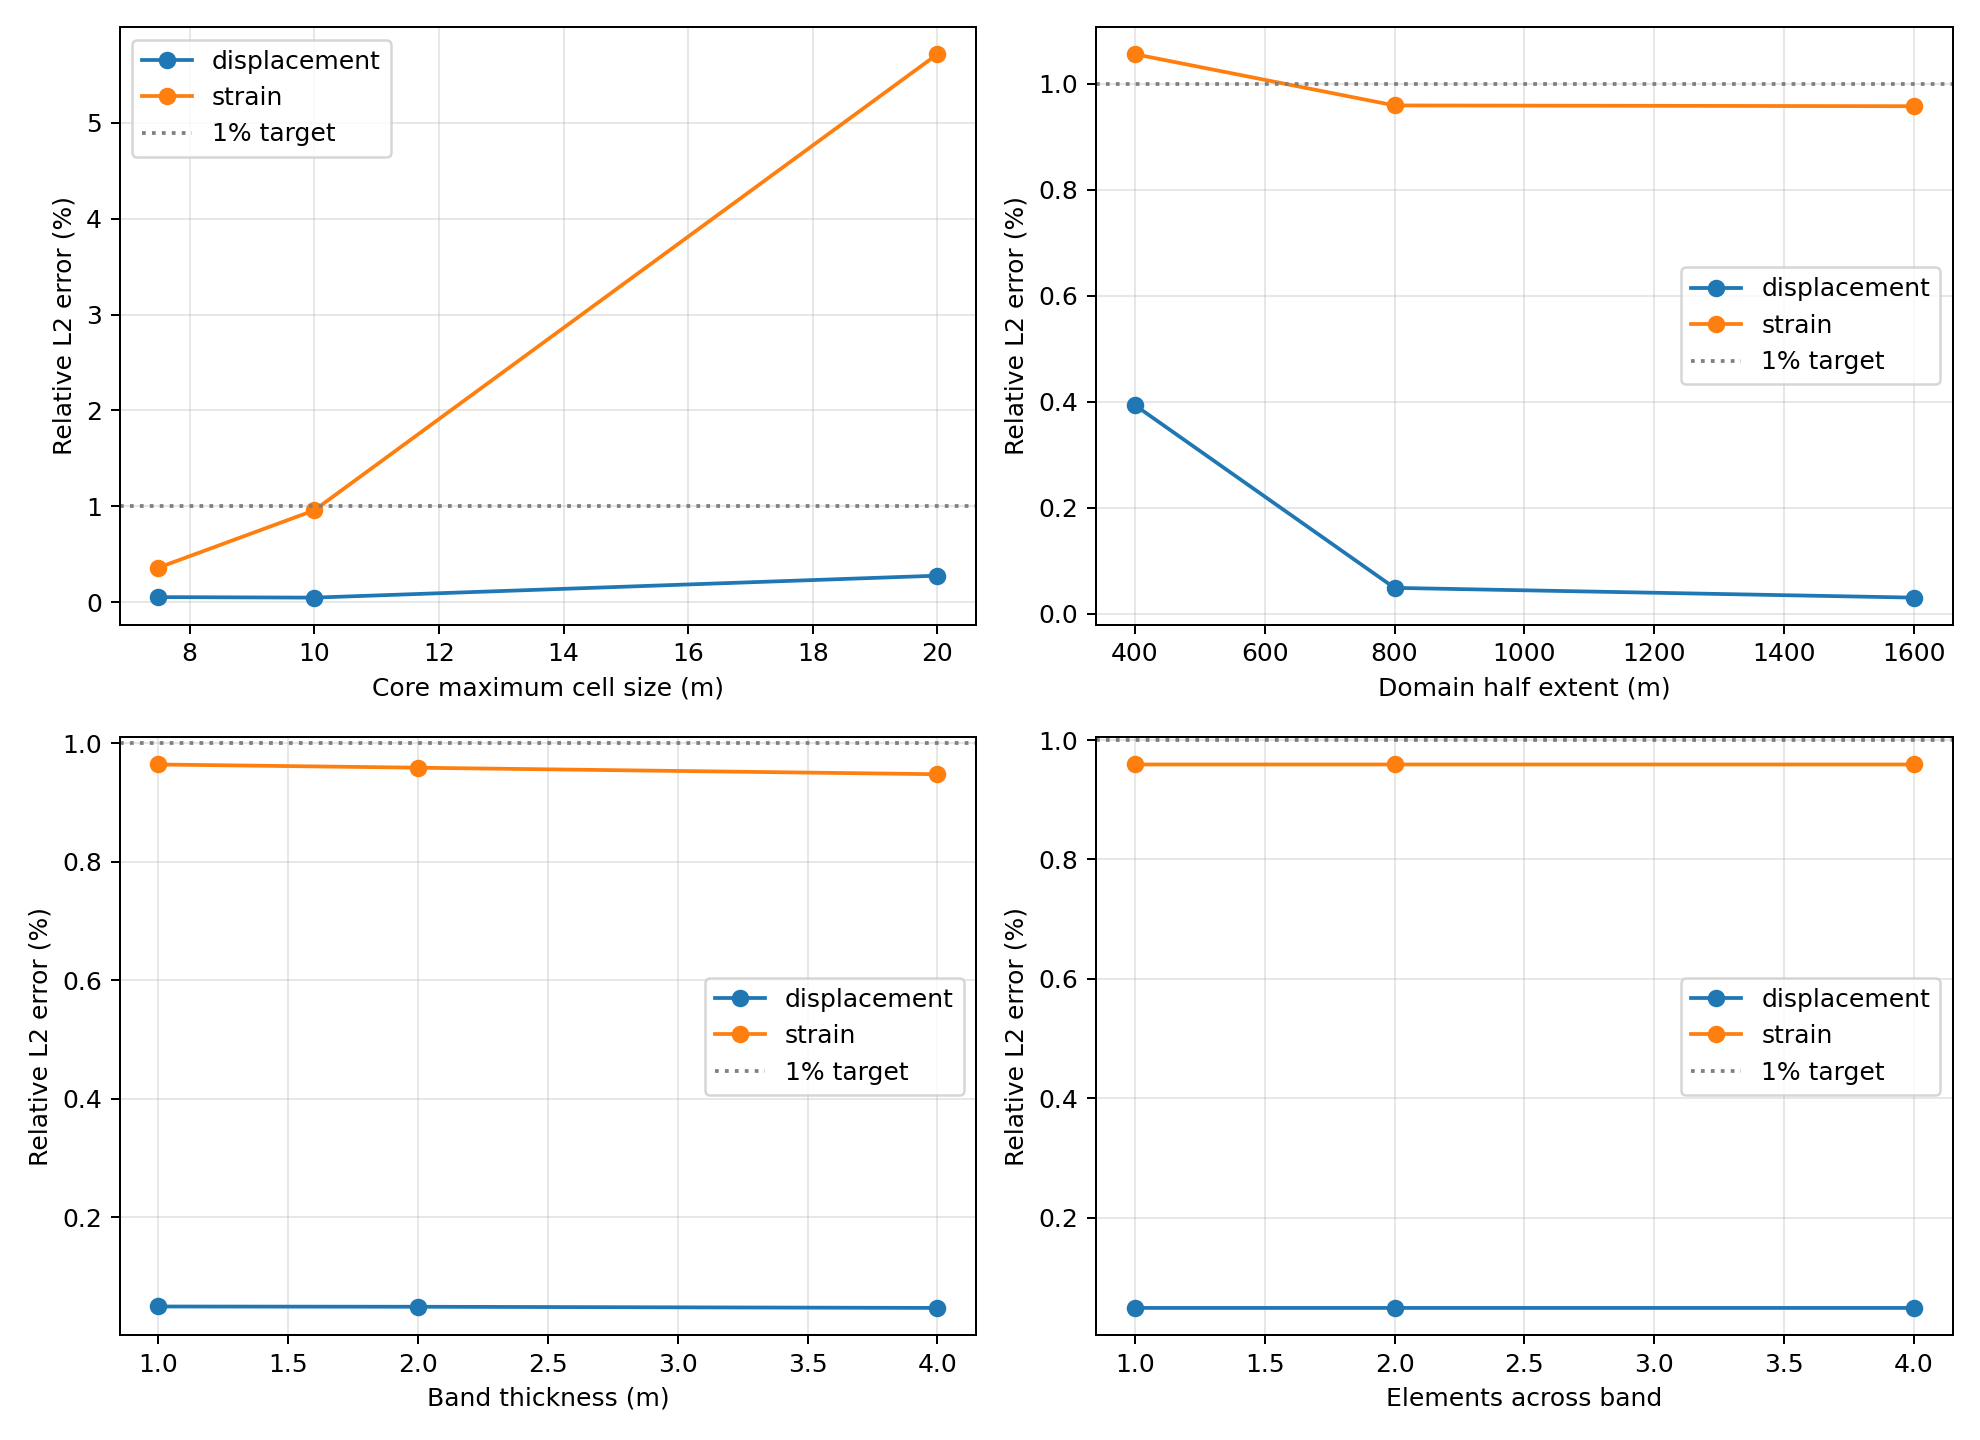

In [8]:
all_results = json.loads((OUT/'all_metrics.json').read_text())
selected = ['opening_h20_L800_t2','opening_h10_L800_t2','opening_h7p5_L800_t2',
            'opening_h10_L400_t2','opening_h10_L1600_t2','opening_h10_L800_t1',
            'opening_h10_L800_t4','opening_h10_L800_t2_b1','opening_h10_L800_t2_b4',
            'opening_h10_L800_t2_q7','s1_h10_L800_t2','s2_h10_L800_t2',
            'mixed_h10_L800_t2','mixed_h7p5_L800_t2']
table=[]
for name in selected:
    if name in all_results:
        m=all_results[name]
        table.append({'算例':name,'位移 L2 (%)':100*m['displacement']['relative_l2'],
                      '应变 L2 (%)':100*m['strain']['relative_l2'],
                      '应变峰值归一化最大误差 (%)':100*m['strain']['peak_normalized_max'],
                      'DOFs':m['dofs'],'墙钟秒':m['run']['elapsed_seconds']})
display(pd.DataFrame(table).set_index('算例'))
display(Image(filename=str(OUT/'convergence.png')))

In [9]:
extensions=json.loads((OUT/'extensions/metrics.json').read_text())
rows=[]
for name,values in extensions.items():
    if isinstance(values,list):
        for i,m in enumerate(values):
            rows.append({'算例 / 井':f'{name} / {i}',
                         '位移 L2 (%)':100*m['displacement']['relative_l2'],
                         '应变 L2 (%)':100*m['strain']['relative_l2']})
display(pd.DataFrame(rows).set_index('算例 / 井'))
display(pd.DataFrame([{'时间历史':name,'应变 L2 (%)':100*extensions[name]['strain']['relative_l2'],
                      '应变率 L2 (%)':100*extensions[name]['rate']['relative_l2']}
                     for name in ['history_fixed','history_geometry']]).set_index('时间历史'))
checks=json.loads((OUT/'physical_checks.json').read_text())
print('零加载最大位移：',checks['zero_load_max_displacement'])
print('张开幅度加倍的线性比例偏差：',checks['opening_linearity']['relative_l2'])
print('旋转一致性偏差：',extensions['rotation_covariance']['relative_l2'])

零加载最大位移： 0.0
张开幅度加倍的线性比例偏差： 1.7957792734005196e-14
旋转一致性偏差： 9.027063401870925e-15


,位移 L2 (%),应变 L2 (%)
算例 / 井,,
multiple_wells / 0,0.048701,0.959025
multiple_wells / 1,0.088881,0.546582
multiple_wells / 2,0.105260,0.145335
rotated_translated / 0,0.048701,0.959025
rotated_translated / 1,0.088881,0.546582
two_rectangles / 0,0.048701,0.959025
discrete_ellipse_5 / 0,0.049336,0.580846
discrete_ellipse_5 / 1,0.101721,0.518648


,应变 L2 (%),应变率 L2 (%)
时间历史,,
history_fixed,0.959025,0.959025
history_geometry,0.923525,3.182569


变化几何的三快照应变率误差约 **3.18%**，高于应变误差，当前不能宣称所有历史均达到1%。
对同一个时间算子，速率误差等于对应变误差求导，已实测确认；连续几何变化的真实时间截断误差尚未在该三快照例中验证。
五条带椭圆比较的是完全相同的矩形条带及跳跃分布，不是用光滑椭圆替换原几何。

穿面井粗网格的应变误差为32.52%，局部加密后降至0.2604%；几何、参考和全部接收点保持相同。

In [10]:
diagnostics=CASE/'diagnostics.json'
if diagnostics.exists():
    d=json.loads(diagnostics.read_text())
    m=json.loads((SAVED/'metrics.json').read_text())
    d={'baseline_L2400_t0p2':{'displacement':m['displacement_final'],'strain':m['strain']},**d}
    display(pd.DataFrame([{'穿面井独立检查':name,
                          '位移 L2 (%)':100*m['displacement']['relative_l2'],
                          '应变 L2 (%)':100*m['strain']['relative_l2']}
                         for name,m in d.items()]).set_index('穿面井独立检查'))
else:
    print('附加的穿面井域大小/厚度检查尚未完成，不作精度结论。')
audit=json.loads((OUT/'reference_0930/audit.json').read_text())
print('0930 原版斜井均匀应变复现：',audit['well_actual'])
print('0930 asymmetric width 请求 / 实际：',audit['asymmetric_width_requested'],audit['asymmetric_width_actual'])
print('原版90°微调相对于精确旋转的最大矩阵差：',audit['vertical_rotation_difference_from_exact'])

0930 原版斜井均匀应变复现： [0.00010000000000000002, 0.00010000000000000002, 0.00010000000000000005, 0.00010000000000000002, 0.00010000000000000002]
0930 asymmetric width 请求 / 实际： 0.001 0.001
原版90°微调相对于精确旋转的最大矩阵差： 0.0009999998333332315


,位移 L2 (%),应变 L2 (%)
穿面井独立检查,,
baseline_L2400_t0p2,0.041080,0.260437
domain_L4800,0.019162,0.260377
thickness_0p1,0.041180,0.260956


## 6. 使用范围与复现入口

- **已实际验证**：纯张开、两个剪切分量、混合跳跃、旋转平移、多矩形、五条带椭圆、多井/倾斜井/曲井标距、固定和变化几何快照，以及本例全部30帧。
- **实现但未单独验证精度**：不同方向裂缝组的 `Model` 叠加、任意独立混合模式历史、强烈重叠薄层、一阶插值。
- **当前限制**：有限域与有限厚度；尖端应力和逐点面力跳跃尚未做收敛验证；原版完整绘图/模块嵌套接口不完全兼容。
  原版全局裂缝内部井位移是局部分量，本接口返回用户输入坐标系下的全局分量。界面/接触、流动、孔弹性、惯性等额外物理不在本次实现中。
- **参考版本**：0930 已修复旧版的方向向量逐分量归一化和width赋值问题；90°微调仍存在。
  旧 `DDMpy_log` 的四项审计与0930审计分别保存，未修改原参考源码。

完整MOOSE输入、命令、日志、CSV、NPZ和指标位于上文 `result_directory`。输入内含网格与载荷定义，可直接在该目录运行 `command.txt`。

从工作区根目录重新运行本例：
```bash
env MPLCONFIGDIR=/tmp/mplconfig ~/miniforge/bin/python scripts/numerical_ddm/reproduce_notebook.py --refine --recycle
```
使用原有moose conda环境重新编译：`bash scripts/numerical_ddm/build.sh`。
没有Jupyter内核时也可刷新本文件的已执行输出：
```bash
~/miniforge/bin/python scripts/numerical_ddm/build_review_notebook.py
```

[数学、编译和运行说明](README.md) · [兼容范围](COMPATIBILITY.md) · [完整实测表](../../output/numerical_ddm/RESULTS.md)
